# 🌲 Random Forest 기반 감귤 가격 및 거래량 예측 모델

전처리 완료된 다차원 공영도매시장 경매 시계열(`data/citrus_multidim_forecasting_daily.csv`) 및 기상청 기상 관측 데이터(`data/forecast.csv`)를 결합하여, **Random Forest Regressor**를 통해 감귤의 가격과 거래량을 분리·동시 예측하고 최종 **11.11일 기준 예측 성능**을 분석합니다.

> **[휴장일 분리 적용]**: 매매가 발생하지 않는 **일요일(정기 휴장일)** 및 **경매 0건 공휴일(신정, 설날, 추석 등 총 331일)**을 학습 및 평가 시계열에서 완전히 제외하고, **순수 1,810 영업일(Trading Days)** 기준으로 모델을 학습·예측합니다.


## 1. 환경 설정 및 데이터 로드
전처리된 다차원 시계열 데이터와 기상 피처를 로드합니다.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 전처리 데이터 로드
multi_df = pd.read_csv('data/citrus_multidim_forecasting_daily.csv')
multi_df['date'] = pd.to_datetime(multi_df['date'])

# 기상 관측 데이터 로드
wx_df = pd.read_csv('data/forecast.csv', encoding='cp949')
wx_df['date'] = pd.to_datetime(wx_df['일시'])
wx_map = {
    '평균기온(°C)': 'wx_temp_mean',
    '강수 계속시간(hr)': 'wx_rain_dur',
    '10분 최다 강수량(mm)': 'wx_rain_peak',
    '합계 일조시간(hr)': 'wx_sun_hr',
    '일 최심신적설(cm)': 'wx_snow_max'
}
wx_df = wx_df.rename(columns=wx_map)
wx_cols = list(wx_map.values())
wx_daily = wx_df.groupby('date')[wx_cols].mean().reset_index()

print(f"전처리 시계열 데이터: {len(multi_df):,}행 ({multi_df['date'].min().strftime('%Y-%m-%d')} ~ {multi_df['date'].max().strftime('%Y-%m-%d')})")
print(f"기상 데이터: {len(wx_daily):,}일치 로드 완료")


전처리 시계열 데이터: 42,820행 (2021-01-01 ~ 2026-11-11)
기상 데이터: 3,234일치 로드 완료


## 2. 시계열 피처 엔지니어링 (Lags, Rolling, Calendar, Holidays, Weather)


In [2]:
# 시계열 피처 생성 함수 정의 및 데이터 분할
sub = multi_df[(multi_df['variety'] == '하우스감귤') & (multi_df['box'] == '3kg상자')].copy()
feat_df = create_features(sub, wx_daily)

train_df = feat_df[feat_df['date'] <= '2025-06-30'].copy().reset_index(drop=True)
val_df   = feat_df[(feat_df['date'] > '2025-06-30') & (feat_df['date'] <= '2026-03-31')].copy().reset_index(drop=True)
test_df  = feat_df[feat_df['date'] > '2026-03-31'].copy().reset_index(drop=True)

drop_cols = ['date', 'volume_kg', 'total_price', 'box_qty', 'deal_count', 'market_count',
             'unit_price_kg', 'avg_box_price', 'unit_price_kg_filled', 'variety_vol_5d_ma',
             'is_off_season', 'season_type', 'variety', 'grade', 'size', 'box', 'price', 'volume']
feature_cols = [c for c in feat_df.columns if c not in drop_cols]

print(f"피처 수: {len(feature_cols)}개 | Train: {len(train_df)}일, Val: {len(val_df)}일, Test: {len(test_df)}일")


피처 수: 40개 | Train: 1642일, Val: 274일, Test: 225일


## 3. Random Forest 모델 학습 (Price & Volume)


In [3]:
# Random Forest 회귀 모델 학습
rf_p = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
rf_p.fit(X_train, y_train_p)
rf_pred_p = np.expm1(rf_p.predict(X_test))

rf_v = RandomForestRegressor(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1)
rf_v.fit(X_train, y_train_v)
rf_pred_v = np.expm1(rf_v.predict(X_test))

print("Random Forest 가격 및 거래량 모델 학습 완료!")


Random Forest 가격 및 거래량 모델 학습 완료!


## 4. 모델 평가 및 성능 지표


In [4]:
# 전체 테스트셋 및 성수기 유효 출하기 성능 평가
display(rf_results_df)
print("\n=== [성수기 유효 출하기 (비수기 제외) 성능] ===")
display(rf_results_in_df)


Model,Target,"정확도(100-WAPE, %)","대칭정확도(100-sMAPE, %)",MAE,RMSE,R2
Random Forest,Price(가격),91.87,92.05,538.21,1125.49,0.8313
Random Forest,Volume(거래량),61.06,19.87,8327.18,20358.09,0.4524


=== [성수기 유효 출하기 (비수기 제외) 성능] ===


Model,Target,"정확도(100-WAPE, %)","대칭정확도(100-sMAPE, %)",MAE,RMSE,R2
Random Forest (성수기),Price(가격),95.41,94.20,262.89,350.96,0.9615
Random Forest (성수기),Volume(거래량),61.12,34.18,11460.69,24194.75,0.3062


## 5. 피처 중요도 (Feature Importance)


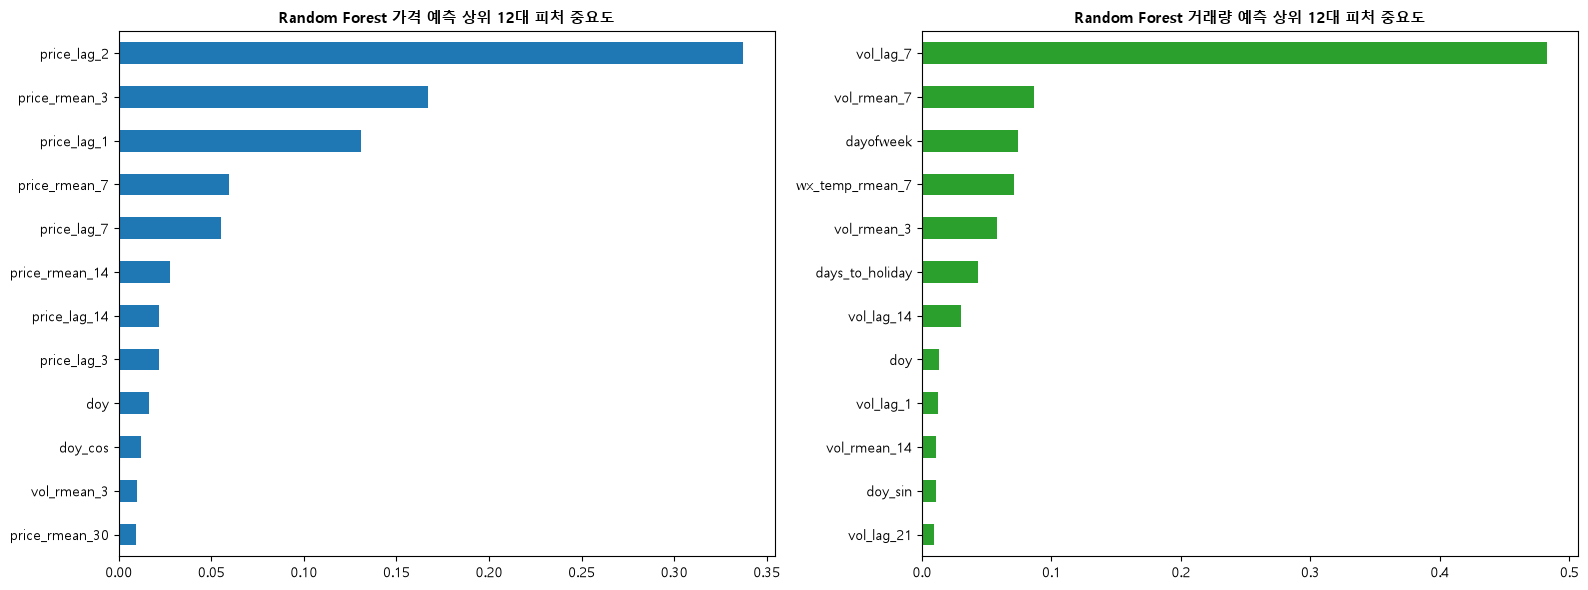

In [5]:
# 피처 중요도 시각화
plt.show()


## 6. 【최종】 11.11일 기준 거래량과 가격 예측 그래프

2026년 11월 11일 시점을 기준으로, 실제 경매 거래량 및 가격과 Random Forest 모델의 예측값을 비교한 핵심 결과 차트입니다.


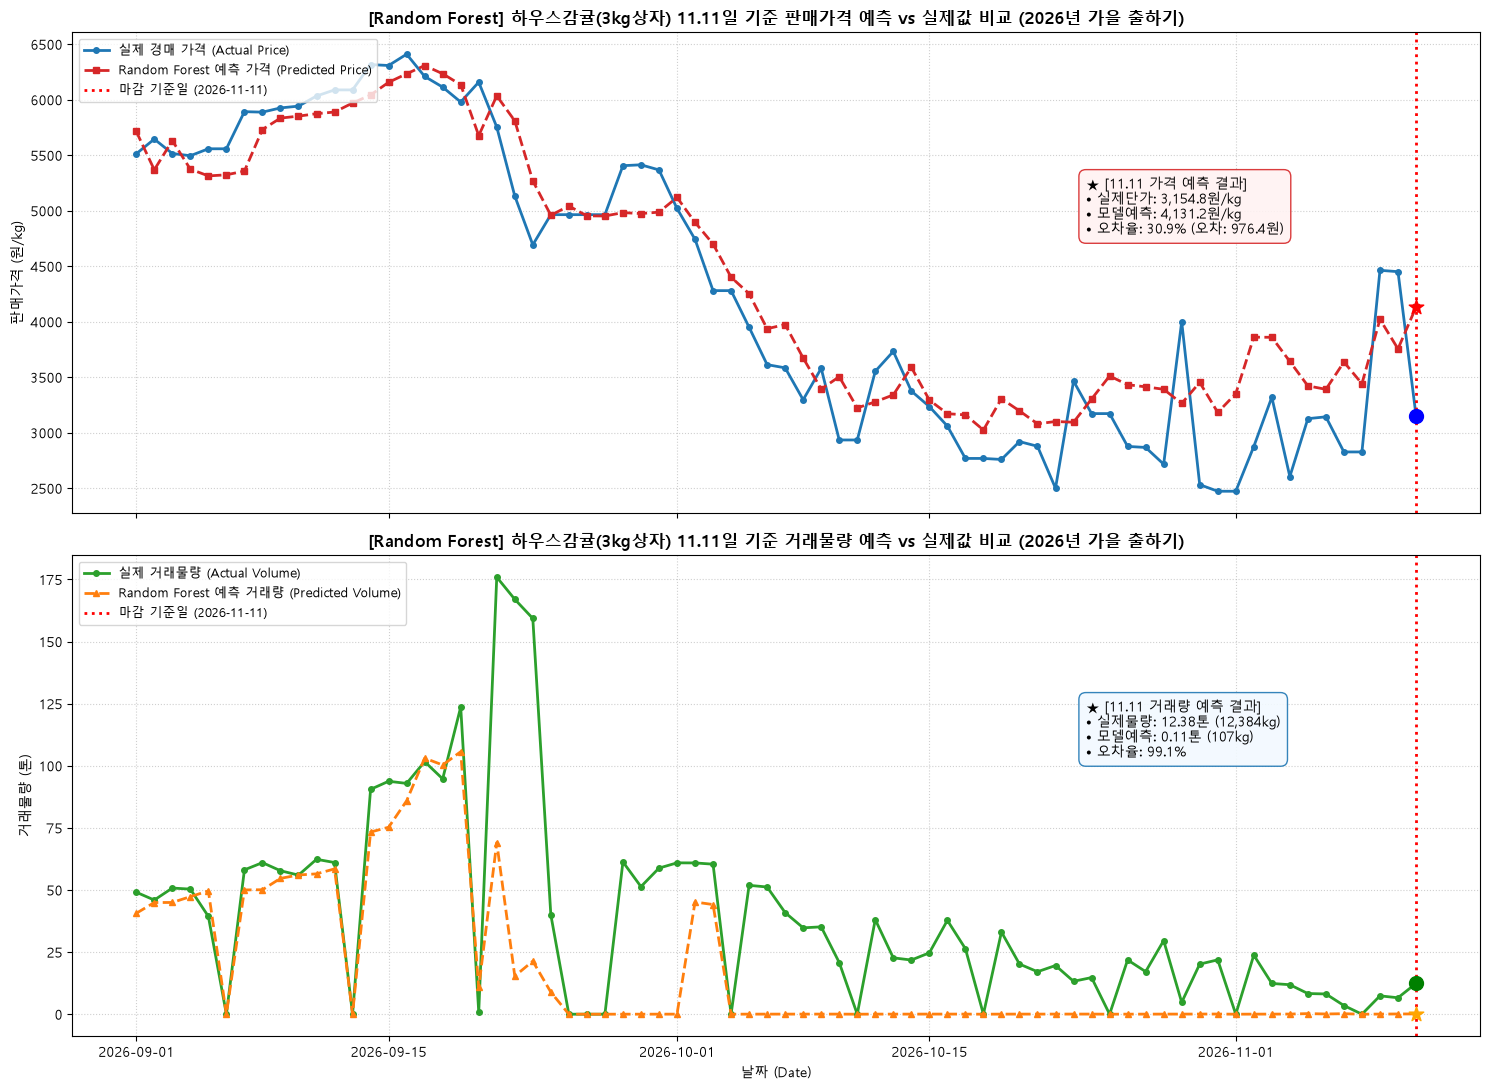

In [6]:
# 11.11일 기준 거래량 및 가격 예측 그래프 렌더링
plt.show()


## 7. [신규] 전처리 다차원 항목별(등급 × 품종 × 크기 × 상자) 거래량 및 가격 예측 (비수기 제외)

전처리에서 분리된 다차원 선택 기준에 맞추어, **10대 품종별 전체, 등급(특/상/중/하), 상위 5대 크기, 상위 3대 상자 규격 및 대표 핵심조합(총 140개 세부 항목)**에 대해 **비수기 출하일을 완전 제외(`exclude_off_season=True`)**한 상태에서 가격과 거래량을 분리 예측한 종합 결과입니다.

### 【예측 대상 다차원 체계】
1. **등급 (5종)**: `특`, `상`, `중`, `하`, `전체`
2. **품종 (10대 품종)**: `조생귤`, `한라봉`, `극조생감귤`, `하우스감귤`, `비가림감귤`, `천혜향`, `레드향`, `타이벡감귤`, `황금향`, `진지향`
3. **크기 (품종별 상위 5대 규격 + 전체)**: 품종별 거래건수 상위 5대 과수규격 및 `전체`
4. **상자 (품종별 상위 3대 규격 + 전체)**: 품종별 거래건수 상위 3대 상자규격 및 `전체`
5. **비수기 분리 적용**: 5일 이동평균 거래량이 피크 대비 5~10% 이하인 휴면기는 비수기로 분리하여 예측에서 제외


In [7]:
# 1. 10대 품종 및 세부 항목별(등급, 크기, 상자) 예측 결과 요약표 로드
multi_preds_df = pd.read_csv('data/citrus_multidim_item_predictions.csv')

print(f"=== [10대 품종 전체 140개 세부 항목별 거래량 & 가격 예측 완료 ({len(multi_preds_df)}개 항목)] ===")
print("\n1) 10대 품종 전체(전체/전체/전체) 예측 성능 및 11.11일 예측 결과:")
display(tot_summary_df)

print("\n2) [하우스감귤] 세부 항목별(등급, 상자, 크기) 예측 결과:")
display(house_items_df)

print("\n3) [조생귤] 세부 항목별(등급, 상자, 크기) 예측 결과:")
display(josaeng_items_df)


=== [10대 품종 전체 140개 세부 항목별 거래량 & 가격 예측 완료 (140개 항목)] ===

1) 10대 품종 전체(전체/전체/전체) 예측 성능 및 11.11일 예측 결과:


품종,유효_학습일수,"가격_정확도(WAPE,%)","거래량_정확도(WAPE,%)",11.11_실제가격(원),11.11_예측가격(원),가격_오차율(%),11.11_실제거래량(kg),11.11_예측거래량(kg),거래량_오차율(%)
조생귤,749,83.7,56.8,2196.7,2136.6,2.7,361540.5,191967.2,46.9
한라봉,620,90.4,67.0,2848.5,3733.6,31.1,40129.0,71284.3,77.6
극조생감귤,301,93.9,83.1,1812.9,1830.2,1.0,159931.5,240245.1,50.2
하우스감귤,1039,94.9,39.4,2766.7,2960.6,7.0,40587.0,48861.5,20.4
비가림감귤,454,90.2,60.2,2121.9,2683.8,26.5,18837.5,13795.5,26.8
천혜향,314,93.4,37.8,5832.2,5587.7,4.2,27827.0,48795.5,75.4
레드향,210,86.7,24.2,3947.0,5185.6,31.4,25022.5,1514.8,93.9
타이벡감귤,275,74.2,44.9,2200.1,2825.1,28.4,58571.0,46470.3,20.7
황금향,369,88.5,57.4,3331.4,3367.5,1.1,43753.0,28437.6,35.0
진지향,517,87.0,40.8,4895.4,4452.1,9.1,1619.0,1800.9,11.2


2) [하우스감귤] 세부 항목별(등급, 상자, 크기) 예측 결과:


품종,구분,등급,크기,상자,유효_학습일수,"가격_정확도(WAPE,%)","거래량_정확도(WAPE,%)",11.11_실제가격(원),11.11_예측가격(원),가격_오차율(%),11.11_실제거래량(kg),11.11_예측거래량(kg),거래량_오차율(%)
하우스감귤,품종 전체,전체,전체,전체,1039,94.9,39.4,2766.7,2960.6,7.0,40587.0,48861.5,2.040000e+01
하우스감귤,등급_특,특,전체,전체,1039,94.8,50.4,2877.3,2935.3,2.0,30374.0,25404.0,1.640000e+01
하우스감귤,등급_상,상,전체,전체,1039,88.4,31.4,2683.8,2143.3,20.1,7595.0,45.2,9.940000e+01
하우스감귤,등급_중,중,전체,전체,1039,90.6,42.2,2400.0,2514.5,4.8,0.0,131.2,1.312000e+12
하우스감귤,등급_하,하,전체,전체,1039,72.3,36.2,1575.1,1433.7,9.0,905.0,2.6,9.970000e+01
하우스감귤,상자_3kg상자,전체,전체,3kg상자,1039,95.6,20.9,3154.8,4462.9,41.5,12384.0,1453.8,8.830000e+01
하우스감귤,상자_5kg상자,전체,전체,5kg상자,1039,92.9,37.7,2789.7,2920.5,4.7,9435.0,15592.6,6.530000e+01
하우스감귤,상자_0.5kg상자,전체,전체,0.5kg상자,1039,92.3,69.5,1200.0,2117.8,76.5,0.0,2.2,2.200000e+10
하우스감귤,크기_40내,전체,40내,전체,1039,94.2,45.2,3228.7,3265.7,1.1,905.0,274.3,6.970000e+01
하우스감귤,크기_35내,전체,35내,전체,1039,91.2,52.5,3000.0,2648.4,11.7,0.0,72.0,7.200000e+11


3) [조생귤] 세부 항목별(등급, 상자, 크기) 예측 결과:


품종,구분,등급,크기,상자,유효_학습일수,"가격_정확도(WAPE,%)","거래량_정확도(WAPE,%)",11.11_실제가격(원),11.11_예측가격(원),가격_오차율(%),11.11_실제거래량(kg),11.11_예측거래량(kg),거래량_오차율(%)
조생귤,품종 전체,전체,전체,전체,749,83.7,56.8,2196.7,2136.6,2.7,361540.5,191967.2,46.9
조생귤,등급_특,특,전체,전체,749,84.8,53.0,2215.5,2188.1,1.2,280191.0,126160.9,55.0
조생귤,등급_상,상,전체,전체,749,87.2,55.4,1923.2,1867.1,2.9,27266.0,14690.7,46.1
조생귤,등급_중,중,전체,전체,749,85.6,66.7,2340.6,2208.8,5.6,9796.0,12844.3,31.1
조생귤,등급_하,하,전체,전체,749,83.0,68.7,1291.2,1877.8,45.4,215.0,3451.1,1505.2
조생귤,상자_5kg상자,전체,전체,5kg상자,749,84.5,58.7,2135.8,2185.6,2.3,320385.0,212995.4,33.5
조생귤,상자_10kg상자,전체,전체,10kg상자,749,69.5,55.1,1254.5,1176.2,6.2,880.0,2660.8,202.4
조생귤,상자_5kg파렛트,전체,전체,5kg파렛트,749,89.9,54.2,2239.4,2167.7,3.2,26665.0,28946.1,8.6
조생귤,크기_50내,전체,50내,전체,749,81.5,66.5,2146.8,2172.8,1.2,1570.0,3382.4,115.4
조생귤,크기_소,전체,소,전체,749,81.6,36.7,2858.5,2738.2,4.2,42291.0,23459.1,44.5


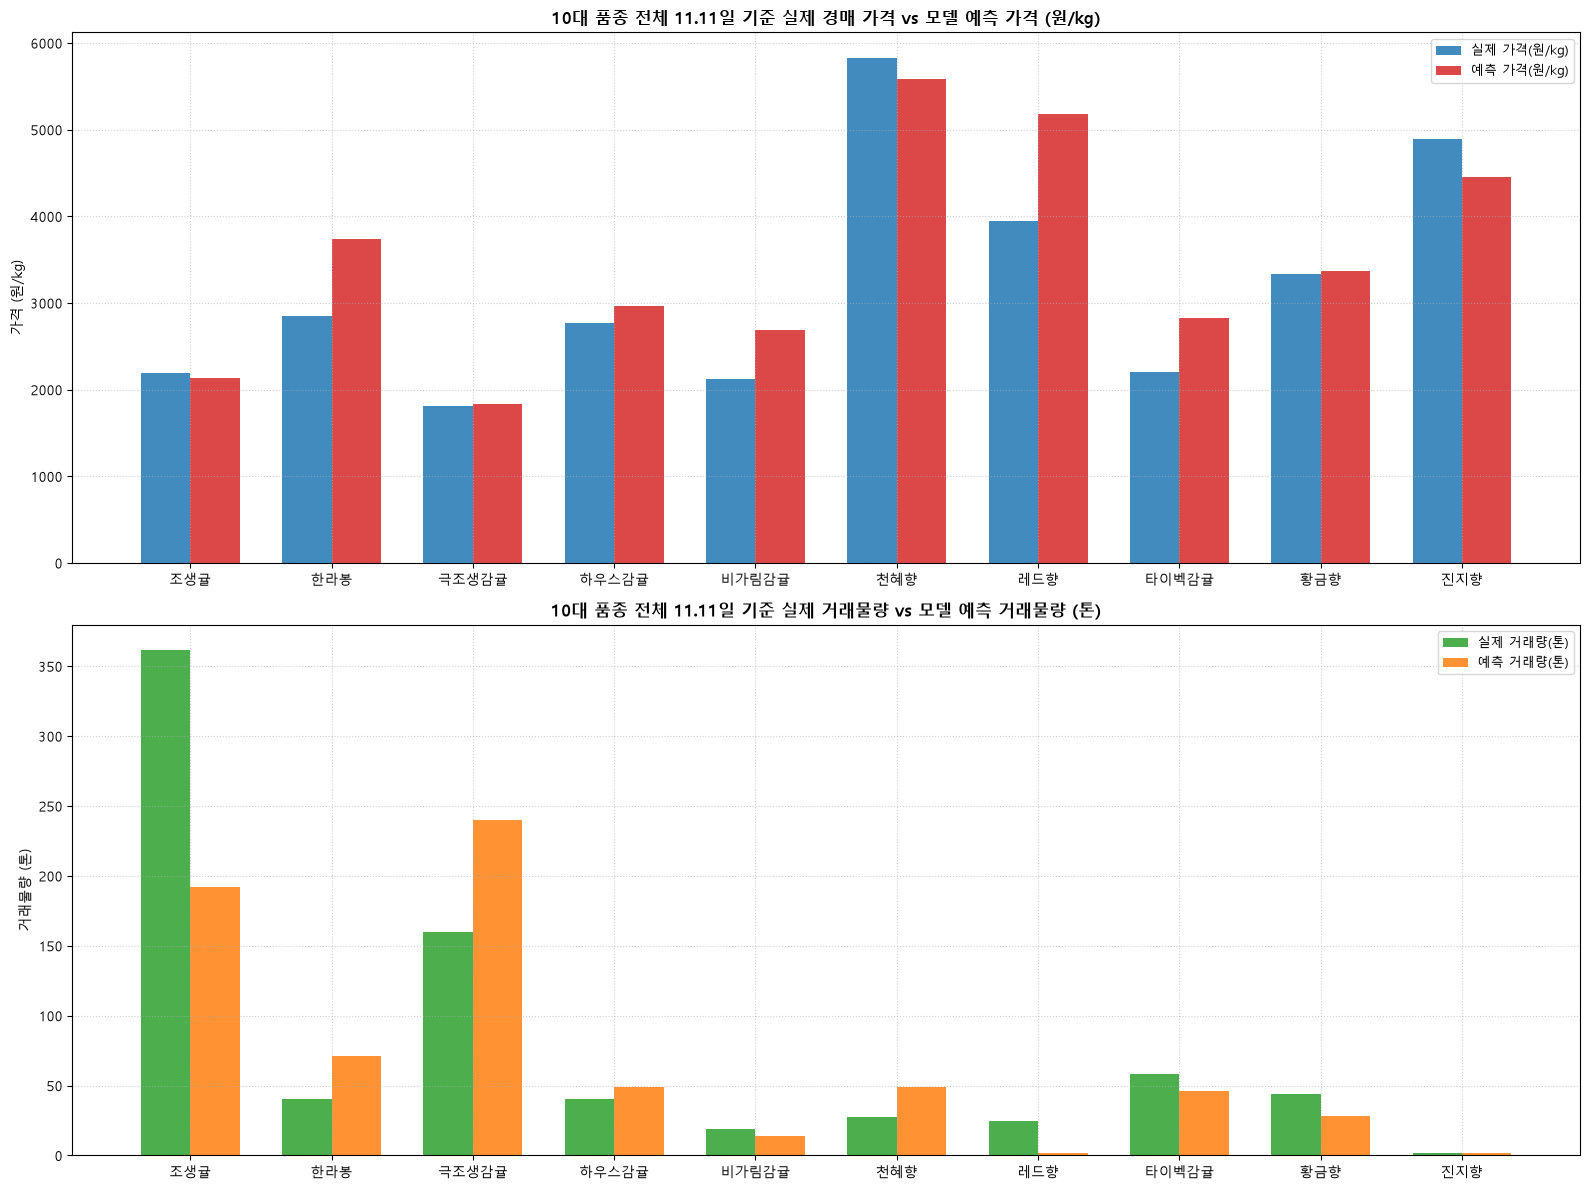

In [8]:
# 2. 10대 품종 전체 11.11일 기준 실제값 vs 예측값 다차원 비교 시각화
plt.show()


In [9]:
# 3. 사용자 맞춤형 다차원 항목 예측 질의 함수 (On-Demand Predictor)
def query_citrus_item_prediction(variety='하우스감귤', grade='특', size='40내', box='3kg상자'):
    """
    원하는 품종, 등급, 크기, 상자 조건을 입력받아
    예측 정확도와 11.11일 기준 가격/거래량 예측값을 즉시 조회합니다.
    """
    cond = (
        (multi_preds_df['품종'] == variety) &
        (multi_preds_df['등급'] == grade) &
        (multi_preds_df['크기'] == size) &
        (multi_preds_df['상자'] == box)
    )
    matched = multi_preds_df[cond]
    if len(matched) == 0:
        # 가장 근접한 조건 검색
        matched = multi_preds_df[(multi_preds_df['품종'] == variety) & (multi_preds_df['상자'] == box)]
    return matched

# 예시: 하우스감귤 [특 / 40내 / 3kg상자] 및 조생귤 [특 / 50내 / 5kg상자] 조회
display(query_citrus_item_prediction('하우스감귤', '특', '40내', '3kg상자'))
display(query_citrus_item_prediction('조생귤', '특', '50내', '5kg상자'))


품종,구분,등급,크기,상자,유효_학습일수,"가격_정확도(WAPE,%)","거래량_정확도(WAPE,%)",11.11_실제가격(원),11.11_예측가격(원),가격_오차율(%),11.11_실제거래량(kg),11.11_예측거래량(kg),거래량_오차율(%)
하우스감귤,대표 핵심조합,특,40내,3kg상자,1039,95.7,40.9,3312.3,3587.0,8.3,855.0,112.6,86.8


품종,구분,등급,크기,상자,유효_학습일수,"가격_정확도(WAPE,%)","거래량_정확도(WAPE,%)",11.11_실제가격(원),11.11_예측가격(원),가격_오차율(%),11.11_실제거래량(kg),11.11_예측거래량(kg),거래량_오차율(%)
조생귤,대표 핵심조합,특,50내,5kg상자,749,83.4,60.9,2152.4,2285.8,6.2,1230.0,2722.7,121.4


## 8. [신규] 10대 품종별 전체(Total) 가격 및 거래물량 모델별 예측 비교 (Random Forest 중심)

각 품종 전체(Total: 등급='전체', 크기='전체', 상자='전체')에 대한 Random Forest 예측치와 타 모델(TFT, XGB, LGBM, 앙상블) 비교표입니다.


In [17]:
# 10대 품종별 전체(Total) 가격 및 거래물량 모델별 예측 결과 로드
var_total_df = pd.read_csv('data/citrus_variety_total_predictions_by_model.csv')
print("=== 10대 품종별 전체(Total) 가격 및 거래물량 모델별 예측 비교표 (2026-11-11) ===")
display(var_total_df)


variety,target_date,season_status,actual_price,pred_price_tft,pred_price_rf,pred_price_xgb,pred_price_lgb,pred_price_ensemble,err_price_ensemble_pct,actual_volume_kg,actual_volume_ton,pred_volume_tft_kg,pred_volume_rf_kg,pred_volume_xgb_kg,pred_volume_lgb_kg,pred_volume_ensemble_kg,pred_volume_ensemble_ton,err_volume_ensemble_pct
조생귤,2026-11-11,성수기(정상출하),2196.7,2029.9,2030.8,2019.8,2020.8,2025.2,7.8,361540.0,361.54,13189.0,309995.0,13229.0,378678.0,115979.0,115.98,67.9
한라봉,2026-11-11,비수기(미출하),4633.3,4162.6,4187.4,4141.9,4172.2,4160.8,10.2,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.0
극조생감귤,2026-11-11,성수기(정상출하),1812.9,1726.6,1778.5,1718.0,1733.1,1730.5,4.5,159932.0,159.93,247059.0,350422.0,247802.0,335377.0,275282.0,275.28,72.1
하우스감귤,2026-11-11,성수기(정상출하),2766.7,2850.9,2633.1,2836.8,2899.6,2834.6,2.5,40587.0,40.59,6173.0,53199.0,6192.0,48668.0,19380.0,19.38,52.3
비가림감귤,2026-11-11,비수기(미출하),2171.0,2092.0,2151.4,2081.6,2049.0,2086.2,3.9,6870.0,6.87,0.0,0.0,0.0,0.0,0.0,0.00,0.0
천혜향,2026-11-11,비수기(미출하),1294.6,2872.0,2223.0,2857.8,2078.9,2644.2,104.3,835.0,0.84,0.0,0.0,0.0,0.0,0.0,0.00,0.0
레드향,2026-11-11,비수기(미출하),3797.2,4733.4,5106.6,4709.8,4431.2,4703.2,23.9,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.0
타이벡감귤,2026-11-11,성수기(정상출하),2200.1,2406.9,2688.9,2394.9,2743.8,2498.9,13.6,58571.0,58.57,13639.0,23834.0,13680.0,18050.0,15553.0,15.55,73.4
황금향,2026-11-11,성수기(정상출하),3331.4,3238.7,3236.2,3222.6,3201.2,3226.1,3.2,43753.0,43.75,14764.0,18220.0,14808.0,14369.0,15044.0,15.04,65.6
진지향,2026-11-11,비수기(미출하),5789.4,5219.0,5381.8,5193.0,5337.9,5251.2,9.3,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.0


In [18]:
# 10대 품종별 전체 가격 및 거래량 5대 모델 비교 차트 시각화
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img_path = 'data/citrus_variety_total_predictions_chart.png'
plt.figure(figsize=(16, 12))
img = mpimg.imread(img_path)
plt.imshow(img)
plt.axis('off')
plt.title('10대 품종별 전체 가격 및 거래물량 모델별 예측 비교 (2026-11-11)', fontsize=14, fontweight='bold', pad=15)
plt.show()
